In [1]:
   %pip install --user -q segmentation-models-pytorch rasterio


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# --- project root: run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

working folder: <project folder>


# 19b — Round 8: U-Net v8 = the v8 recipe with a U-Net instead of SegFormer

Same as notebook 19 (all 12 months + 18 year statistics, **label borders ignored in training**, `data_r5`), but the 2-D network
after the temporal encoder is a **U-Net (ResNet-34, ImageNet start)** instead of SegFormer. U-Net copies fine details from the
encoder to the decoder ("skip connections"), so it may draw sharper field and road edges — which fits well with cleaner border labels.

| | SegFormer v8 (notebook 19) | U-Net v8 (this notebook) |
|---|---|---|
| Temporal encoder, year statistics, fusion | same | same |
| Label borders ignored | yes (1 px) | yes (1 px) |
| 2-D network | SegFormer MiT-B2 (24.8 M) | U-Net ResNet-34 (24.5 M) |
| Learning rate (pretrained encoder) | 6e-5 | 1e-4 (CNNs usually like a slightly higher rate) |

Results go to `runs/A_unet_v8_border/`; notebook 15 then shows it as "v8 U-Net" next to the other models.

## 1. Settings

In [3]:
CFG = dict(
    RUN_NAME="A_unet_v8_border", MODEL_NAME="U-Net v8 (temporal + label borders ignored)",
    ARCH="temporal_unet_resnet34", SEG_ARCH="unet_resnet34", FEATURES="12months+yearstats18+border_ignore",
    DATA="data_r5", WEIGHTS="imagenet",
    EPOCHS=60, WARMUP_EPOCHS=5, BATCH_SIZE=8, EVAL_BATCH=2,
    LR=1e-4, LR_NEW=1e-3, WEIGHT_DECAY=0.01, PATIENCE=12, LOSS="lovasz",
    NOISE_DB=2.0, ROLL=True, MONTH_DROP=0.1, TEMP_DIM=24, FUSE_DIM=32,
    NUM_WORKERS=0, SEED=42,
    BORDER_PX=1)                       # 1 = ignore pixels within 1 px of another class (3 x 3 window); 0 = off (= v6)
# Out of GPU memory? -> BATCH_SIZE=4 (and restart the kernel).

## 2. Setup

In [4]:
import json, random
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from preprocess import CLASSES, COLORS, IGNORE, load_stats
from train_lib_r8 import *                                     # = train_lib_r6 + border ignore

random.seed(CFG["SEED"]); np.random.seed(CFG["SEED"]); torch.manual_seed(CFG["SEED"])
RUN = Path("runs") / CFG["RUN_NAME"]; RUN.mkdir(parents=True, exist_ok=True)
json.dump(CFG, open(RUN / "config.json", "w"), indent=2)
DATA = Path(CFG["DATA"])
mstats = load_stats(DATA / "norm_stats.json")                 # monthly VV, VH, VV-VH mean / std (as v5)
index = pd.read_csv(DATA / "patch_index.csv")
index["file"] = index["file"].str.replace("\\", "/", regex=False)
print("device:", DEV, "|", torch.cuda.get_device_name(0) if DEV == "cuda" else "no GPU - training would be very slow")
print(index.split.value_counts().to_dict())

device: cuda | NVIDIA RTX A6000
{'train': 950, 'val': 128, 'test': 96}


## 3. Step 2 — the 18 year statistics
Computed per pixel over the 12 months. Their average and spread over the training patches are used to rescale them
(computed once from 300 training patches and saved as `data_r5/norm_stats_r6_yearstats.json`).

In [5]:
ystats = year_stat_norm(index, DATA)
display(pd.DataFrame({"mean": ystats["mean"], "std": ystats["std"]}, index=ystats["names"]).round(2).T)

,VV_median,VV_p10,VV_p90,VV_min,VV_max,VV_range,VH_median,VH_p10,VH_p90,VH_min,VH_max,VH_range,VV_VH_median,VV_VH_p10,VV_VH_p90,VV_VH_min,VV_VH_max,VV_VH_range
mean,-11.48,-13.17,-9.80,-13.97,-8.96,5.01,-19.19,-21.11,-17.29,-22.00,-16.38,5.61,7.68,5.69,9.68,4.73,10.72,5.99
std,4.88,5.07,4.72,5.17,4.69,2.38,5.23,5.44,5.01,5.54,5.00,2.91,2.23,2.17,2.48,2.28,2.73,2.44


### Step 1 — what "ignore label borders" removes
Left: the WorldCover label of a training tile. Middle: the pixels that are ignored (black). Right: the label the model learns from.
The table counts, over a sample of training tiles, how many pixels of each class are ignored.

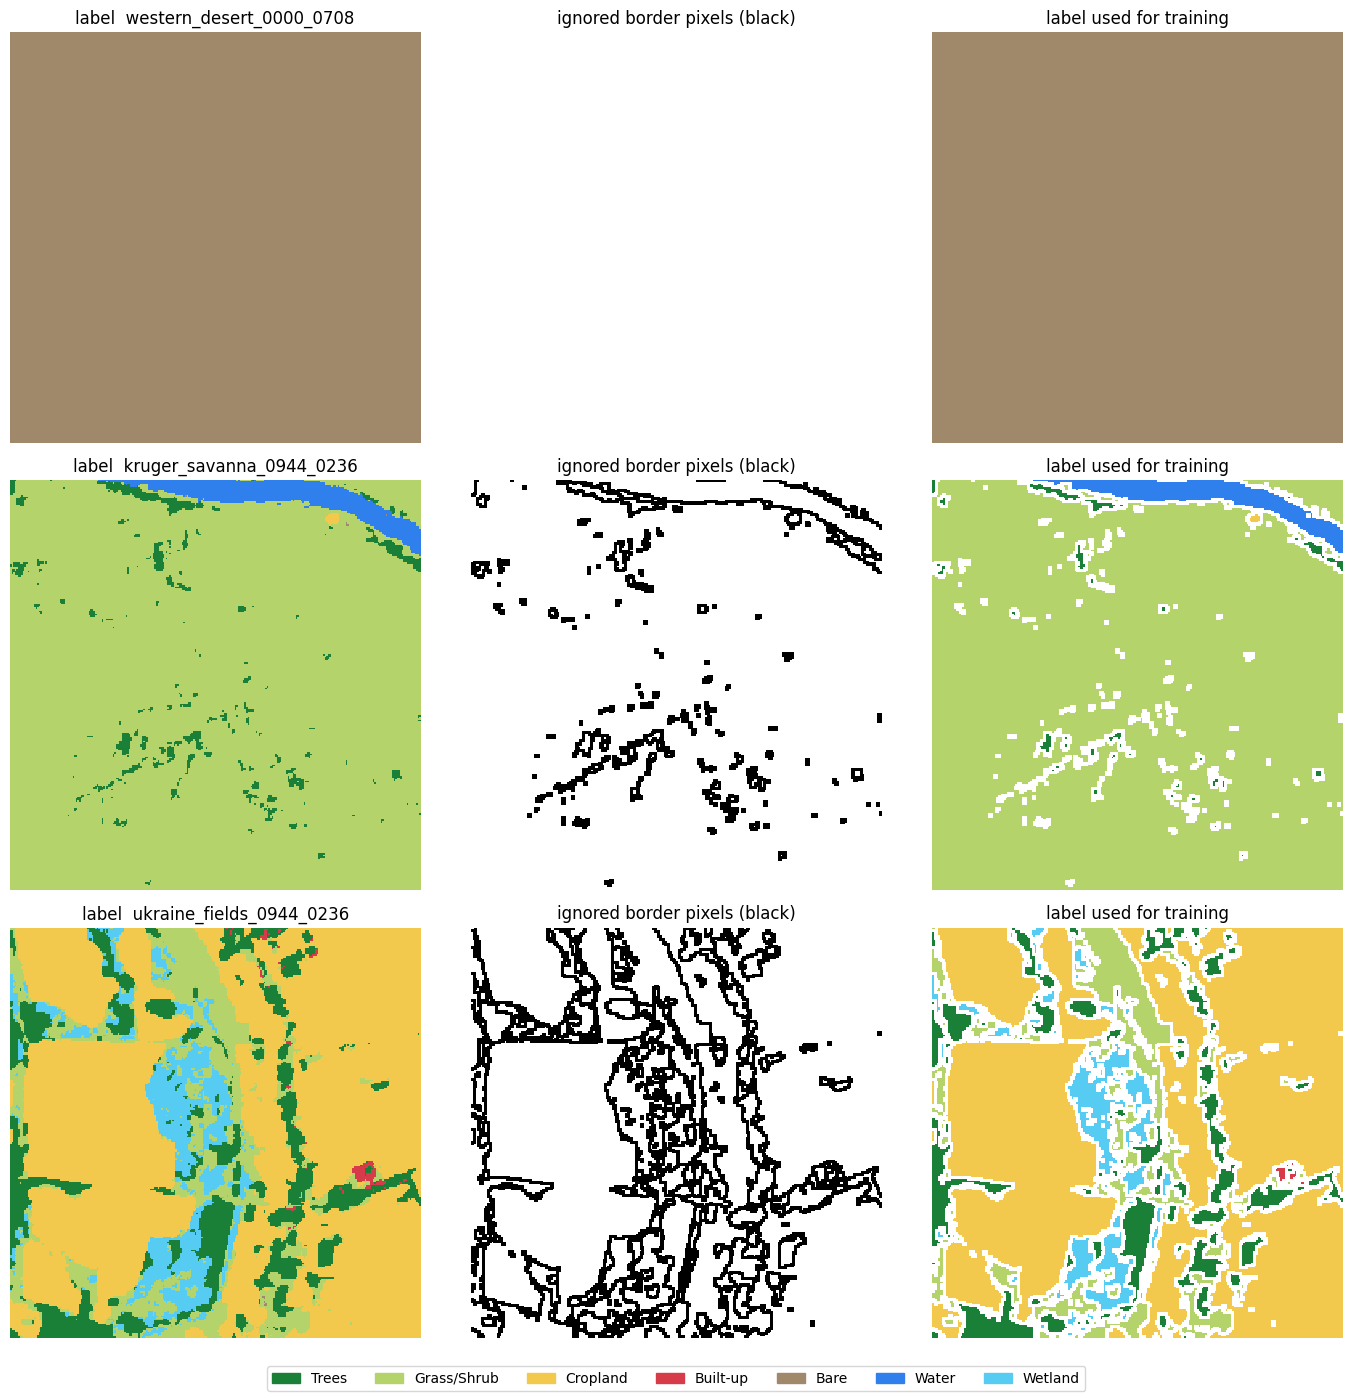

Training pixels ignored overall: 15.3 %  (sample of 200 tiles)


,pixels before,pixels after,ignored %,share before %,share after %
Trees,1502122.0,1070440.0,28.7,11.5,9.6
Grass/Shrub,2953807.0,2422279.0,18.0,22.5,21.8
Cropland,2134684.0,1922805.0,9.9,16.3,17.3
Built-up,2248725.0,1706763.0,24.1,17.2,15.4
Bare,1337306.0,1180100.0,11.8,10.2,10.6
Water,1537974.0,1499064.0,2.5,11.7,13.5
Wetland,1392582.0,1295860.0,6.9,10.6,11.7


In [6]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(COLORS)
tr = index[index.split == "train"]
fig, ax = plt.subplots(3, 3, figsize=(14, 14))
for row, f in zip(ax, tr.file.sample(3, random_state=3)):
    y = np.load(DATA / f)["y"]
    yb = ignore_borders(y, CFG["BORDER_PX"])
    row[0].imshow(np.ma.masked_equal(y, IGNORE), cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); row[0].set_title(f"label  {Path(f).stem}")
    row[1].imshow((yb == IGNORE) & (y != IGNORE), cmap="gray_r", interpolation="nearest"); row[1].set_title("ignored border pixels (black)")
    row[2].imshow(np.ma.masked_equal(yb, IGNORE), cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); row[2].set_title("label used for training")
    for a in row: a.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], CLASSES, loc="lower center", ncol=7)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig(RUN / "border_examples.png", dpi=100); plt.show()

before = np.zeros(len(CLASSES)); after = np.zeros(len(CLASSES))
for f in tr.file.sample(min(200, len(tr)), random_state=0):
    y = np.load(DATA / f)["y"]; yb = ignore_borders(y, CFG["BORDER_PX"])
    before += np.bincount(y[y != IGNORE], minlength=len(CLASSES)); after += np.bincount(yb[yb != IGNORE], minlength=len(CLASSES))
tab = pd.DataFrame({"pixels before": before, "pixels after": after, "ignored %": (1 - after / before) * 100,
                    "share before %": before / before.sum() * 100, "share after %": after / after.sum() * 100}, index=CLASSES)
print(f"Training pixels ignored overall: {(1 - after.sum() / before.sum()) * 100:.1f} %  (sample of {min(200, len(tr))} tiles)")
display(tab.round(1)); tab.to_csv(RUN / "border_ignored_pixels.csv")

## 4. Data and model

In [7]:
train_dl, val_dl = make_loaders_border(CFG, DATA, index)
model = build_model(CFG, mstats, ystats, CFG["WEIGHTS"]).to(DEV)
loss_fn = make_loss(CFG, mstats)
print(f"parameters: {count_params(model):.1f} M  (same as v6) - temporal encoder + fusion: "
      f"{(count_params(model.temporal) + count_params(model.fuse)) * 1000:.1f} k")

# quick check: one batch through the model
x, m, y = next(iter(train_dl))
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
    out = model(x.to(DEV), m.to(DEV))
print("input", tuple(x.shape), "(batch, months, bands, H, W) | output", tuple(out.shape), "(batch, classes, H, W)")

loading val:   0%|          | 0/128 [00:00<?, ?it/s]

train patches 950 (label borders of 1 px ignored) | val patches 128 (full labels, x 12 months each)


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

parameters: 24.5 M  (same as v6) - temporal encoder + fusion: 7.1 k
input (8, 12, 3, 256, 256) (batch, months, bands, H, W) | output (8, 7, 256, 256) (batch, classes, H, W)


## 5. Train
Resumes automatically from `last.pth` if the kernel stops. One epoch ≈ a few minutes on the GPU.

In [8]:
history = train(model, CFG, RUN, train_dl, val_dl, loss_fn)

epoch 0:   0%|          | 0/118 [00:00<?, ?it/s]

ep  0 | train 2.301 | val 2.113 | OA 0.602 | mIoU 0.361  *best* | 63s


epoch 1:   0%|          | 0/118 [00:00<?, ?it/s]

ep  1 | train 1.798 | val 1.729 | OA 0.713 | mIoU 0.472  *best* | 61s


epoch 2:   0%|          | 0/118 [00:00<?, ?it/s]

ep  2 | train 1.562 | val 1.621 | OA 0.741 | mIoU 0.509  *best* | 61s


... (58 outputs left out)

epoch 32:   0%|          | 0/118 [00:00<?, ?it/s]

ep 32 | train 0.571 | val 1.364 | OA 0.798 | mIoU 0.601 | 86s


epoch 33:   0%|          | 0/118 [00:00<?, ?it/s]

ep 33 | train 0.561 | val 1.479 | OA 0.764 | mIoU 0.565 | 83s
Early stopping.
Done. Best val mIoU: 0.6162


## 6. Results on validation (best checkpoint)

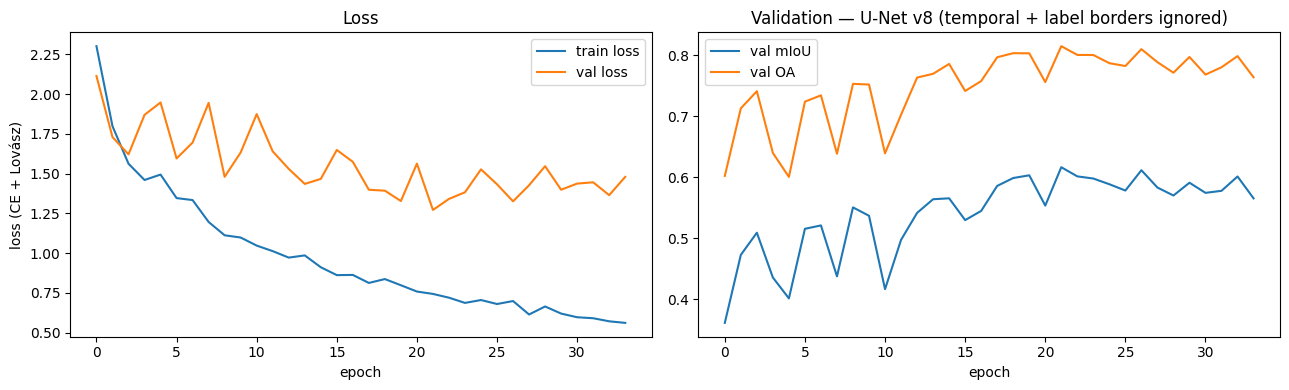

U-Net v8 (temporal + label borders ignored) - val: OA 0.815 | mIoU 0.616 | best / worst month mIoU 0.623 / 0.613 (spread 0.010)


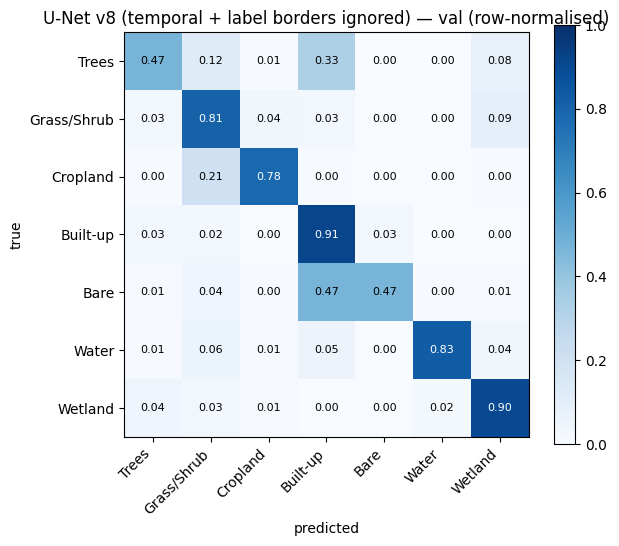

Validation IoU


,SegFormer v6,SegFormer v8,U-Net v8,U-Net v8 - SegFormer v8
Trees,0.441,0.413,0.381,-0.032
Grass/Shrub,0.705,0.700,0.662,-0.038
Cropland,0.693,0.733,0.693,-0.040
Built-up,0.790,0.788,0.780,-0.008
Bare,0.291,0.293,0.292,-0.001
Water,0.751,0.765,0.718,-0.047
Wetland,0.879,0.889,0.787,-0.102
mIoU,0.650,0.654,0.616,-0.038


In [9]:
plot_curves(RUN, CFG["MODEL_NAME"])
model.load_state_dict(torch.load(RUN / "best.pth", map_location=DEV))
val_table, val_month = report(model, CFG, RUN, val_dl, "val")

v6 = json.load(open("runs/C_segformer_v6/metrics.json")); s8 = json.load(open("runs/C_segformer_v8_border/metrics.json"))
cmp = pd.DataFrame({"SegFormer v6": pd.Series(v6["per_class_iou"]), "SegFormer v8": pd.Series(s8["per_class_iou"]),
                    "U-Net v8": val_table["IoU"].drop("mean")})
cmp.loc["mIoU"] = [v6["val_miou"], s8["val_miou"], val_table.loc["mean", "IoU"]]
cmp["U-Net v8 - SegFormer v8"] = cmp["U-Net v8"] - cmp["SegFormer v8"]
print("Validation IoU"); display(cmp.round(3))

## 7. Do the months differ now?
Check that ignoring borders did not make the maps less stable over the months. Below: mIoU per month (validation) and four months of one validation tile.

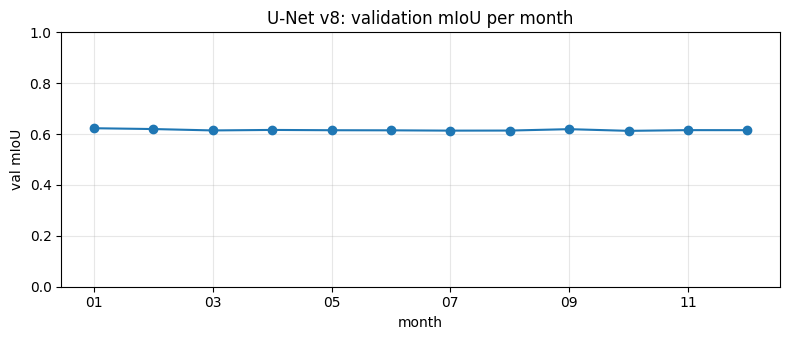

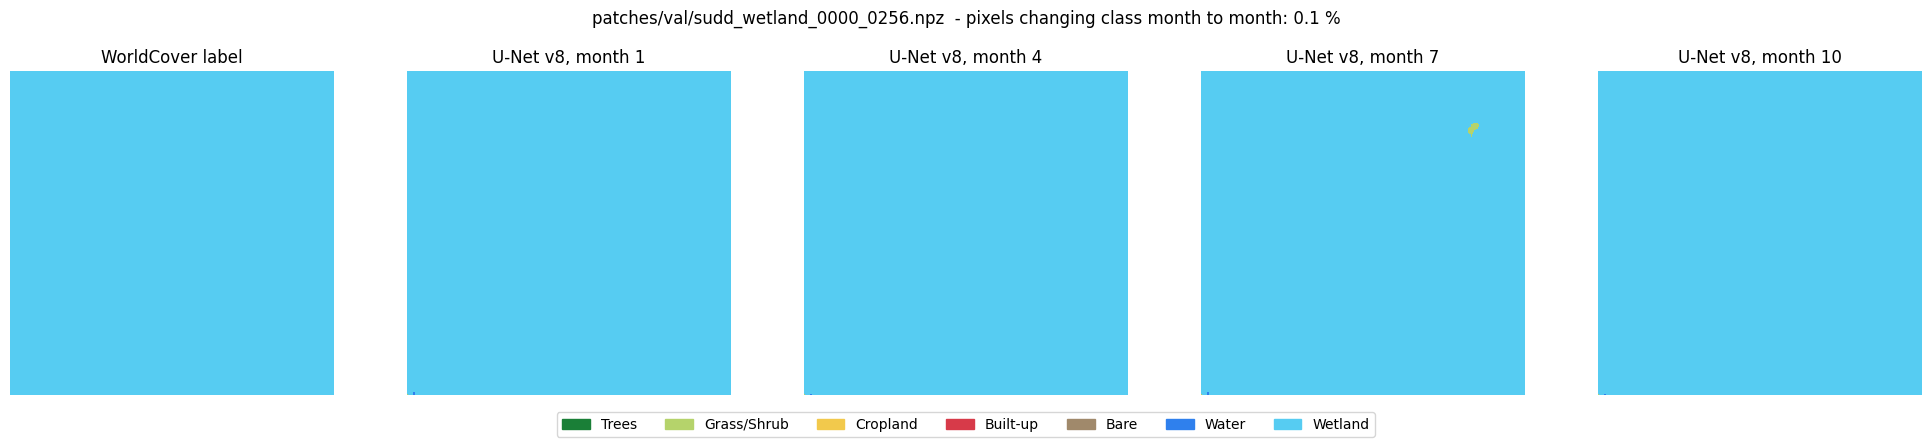

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
val_month.plot(ax=ax, marker="o"); ax.set_ylim(0, 1); ax.set_xlabel("month"); ax.set_ylabel("val mIoU"); ax.grid(alpha=0.3)
ax.set_title("U-Net v8: validation mIoU per month"); plt.tight_layout(); plt.show()

from matplotlib.colors import ListedColormap
cmap = ListedColormap(COLORS)
ds = val_dl.dataset
k = int(np.argmax([float((y_ == 2).float().mean() + (y_ == 6).float().mean()) for y_ in ds.ys]))   # a tile with crop / wetland
x, y = ds[k]
with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
    e = model.encode(x[None].to(DEV))
    preds = [model.decode(e, torch.tensor([m], device=DEV)).argmax(1)[0].cpu().numpy() for m in range(12)]
changed = np.mean([(preds[m] != preds[m - 1]).mean() for m in range(1, 12)]) * 100
fig, ax = plt.subplots(1, 5, figsize=(20, 4.4))
ax[0].imshow(np.ma.masked_equal(y.numpy(), IGNORE), cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); ax[0].set_title("WorldCover label")
for a, m in zip(ax[1:], [0, 3, 6, 9]):
    a.imshow(preds[m], cmap=cmap, vmin=0, vmax=len(CLASSES) - 1, interpolation="nearest"); a.set_title(f"U-Net v8, month {m + 1}")
for a in ax: a.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], CLASSES, loc="lower center", ncol=7)
fig.suptitle(f"{ds.files[k]}  - pixels changing class month to month: {changed:.1f} %")
plt.tight_layout(rect=(0, 0.07, 1, 0.95)); plt.savefig(RUN / "val_months_example.png", dpi=110); plt.show()

## 8. Test set (final exam — only for reporting, not for choosing settings)
Same 6 test regions as SegFormer v6 and v8 (values read from their `metrics.json`).

loading test:   0%|          | 0/96 [00:00<?, ?it/s]

U-Net v8 (temporal + label borders ignored) - test: OA 0.801 | mIoU 0.668 | best / worst month mIoU 0.670 / 0.666 (spread 0.004)


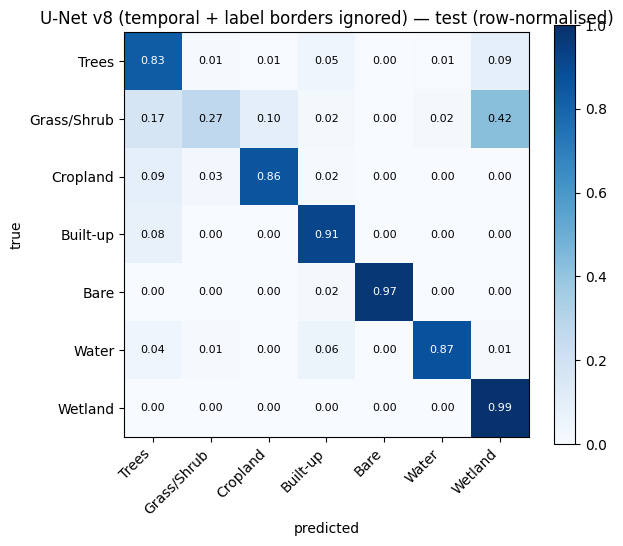

,SegFormer v6,SegFormer v8,U-Net v8,U-Net v8 - SegFormer v8
Trees,0.695,0.694,0.660,-0.034
Grass/Shrub,0.503,0.511,0.257,-0.254
Cropland,0.714,0.722,0.742,0.020
Built-up,0.842,0.837,0.834,-0.003
Bare,0.969,0.964,0.968,0.004
Water,0.848,0.837,0.752,-0.085
Wetland,0.540,0.599,0.466,-0.133
mIoU,0.730,0.738,0.668,-0.070


saved: ['best.pth', 'border_examples.png', 'border_ignored_pixels.csv', 'config.json', 'curves.png', 'history.csv', 'last.pth', 'metrics.json', 'test_confusion.png', 'test_per_class.csv', 'val_confusion.png', 'val_months_example.png', 'val_per_class.csv']


In [11]:
test_ds = EvalSeries(index[index.split == "test"].file, DATA, "loading test")
test_dl = torch.utils.data.DataLoader(test_ds, CFG["EVAL_BATCH"], shuffle=False)
test_table, test_month = report(model, CFG, RUN, test_dl, "test")
t = pd.DataFrame({"SegFormer v6": pd.Series(v6.get("test_per_class_iou", {})), "SegFormer v8": pd.Series(s8.get("test_per_class_iou", {})),
                  "U-Net v8": test_table["IoU"].drop("mean")})
t.loc["mIoU"] = [v6.get("test_miou", np.nan), s8.get("test_miou", np.nan), test_table.loc["mean", "IoU"]]
t["U-Net v8 - SegFormer v8"] = t["U-Net v8"] - t["SegFormer v8"]
display(t.round(3))
print("saved:", sorted(p.name for p in RUN.iterdir()))

✅ **Share with me:** the training curves and the two IoU tables (SegFormer v6 / SegFormer v8 / U-Net v8).
Then run **notebook 15** on your place: the U-Net appears there as "v8 U-Net".